# M10: Cross-country comparison (India first)

**Paper section covered:** none (Part B, work beyond the paper). Extension E8.

## The gap
The paper studies **one country** (the United States) and draws general conclusions: that the airport network is "hub dominated" (gamma below 2), "designed for efficiency", and "vulnerable to targeted attacks", with a cascade threshold "on the lower side", and it recommends protecting hubs. It never asks whether the US is typical. We repeat the analysis of M1 to M9 on **every country with at least 30 airports in the data** (24 countries), plus a European network and the world network, and ask:

1. **Is the US typical?** Which of the paper's conclusions hold elsewhere, and which are specific to the US?
2. **Is India more fragile than the US?** (India is dominated by two hubs, Delhi and Mumbai.)
3. **What structural property explains fragility across countries?** Notably, the paper's claim (from M2) that the biggest hub grows linearly with network size ("k_max ~ N") can finally be tested, because we have many networks of different sizes.

## What the data can and cannot do
Each country network joins airports by **domestic** routes (any airline), keeping the largest connected component. It is the OpenFlights snapshot of 2014 (see M0), whose coverage varies by country and which has no traffic information outside the US (so all analysis here is unweighted, as in the paper's main results). Small networks (30 to 70 airports) give noisy statistics; we use the many small countries together rather than reading too much into any one of them. Europe and the world are built differently: **all routes between airports of the region**, including international ones.

## Plan
| Part | Content |
|---|---|
| A | The networks |
| B | Structure: hubs, degree inequality, clustering, paths; the k_max ~ N test |
| C | Heavy tails and communities |
| D | Attacks: random versus targeted |
| E | Cascades: the threshold model of M6 and the load model of M9 |
| F | What explains fragility across countries? |
| G | India in detail |
| H | Verdict |

## 1. Setup

In [1]:
import sys, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn, regions as rg, attacks as at, cascade as cs

warnings.filterwarnings("ignore")
pd.set_option("display.width", 185)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2"
rng = np.random.default_rng(2025)

airports, routes = usfn.load_openflights()
print(f"OpenFlights: {len(airports):,} airports, {len(routes):,} route rows, {airports.country.nunique()} countries")

OpenFlights: 7,698 airports, 67,663 route rows, 237 countries


## Part A. The networks

We build a domestic network for every country that has at least 30 airports in its largest connected component, and two multi-country networks (Europe, and the whole world).

In [2]:
MIN_N = 30
nets = {}
for c in airports.country.dropna().unique():
    g = rg.build_region_network(airports, routes, [c])
    if g.number_of_nodes() >= MIN_N: nets[c] = g
domestic = sorted(nets, key=lambda c: -nets[c].number_of_nodes())
europe = rg.build_region_network(airports, routes, rg.EUROPE)
world = rg.build_region_network(airports, routes, None)

rows = []
for name, g in [(c, nets[c]) for c in domestic] + [("Europe (international)", europe), ("World (international)", world)]:
    dg = dict(g.degree()); h = max(dg, key=dg.get)
    rows.append({"network": name, "airports": g.number_of_nodes(), "edges": g.number_of_edges(), "largest hub": f"{h} ({g.nodes[h]['city']})", "hub degree": dg[h]})
tab = pd.DataFrame(rows); tab.style.hide(axis="index")

network,airports,edges,largest hub,hub degree
United States,541,2780,ATL (Atlanta),153
Canada,204,434,YVR (Vancouver),34
China,175,1362,PEK (Beijing),110
Brazil,124,370,VCP (Campinas),50
Australia,113,227,SYD (Sydney),45
Russia,112,352,DME (Moscow),70
India,71,198,BOM (Mumbai),45
Indonesia,64,151,CGK (Jakarta),31
Japan,62,175,HND (Tokyo),49
Mexico,56,161,MEX (Mexico City),51


The United States is by far the largest domestic network (541 airports), followed by Canada, China, Brazil, Australia and Russia. **India has 71 airports in the data, and Mumbai (BOM) is its largest hub.** The 24 domestic networks span a factor of 17 in size.

### A1. India and the US side by side

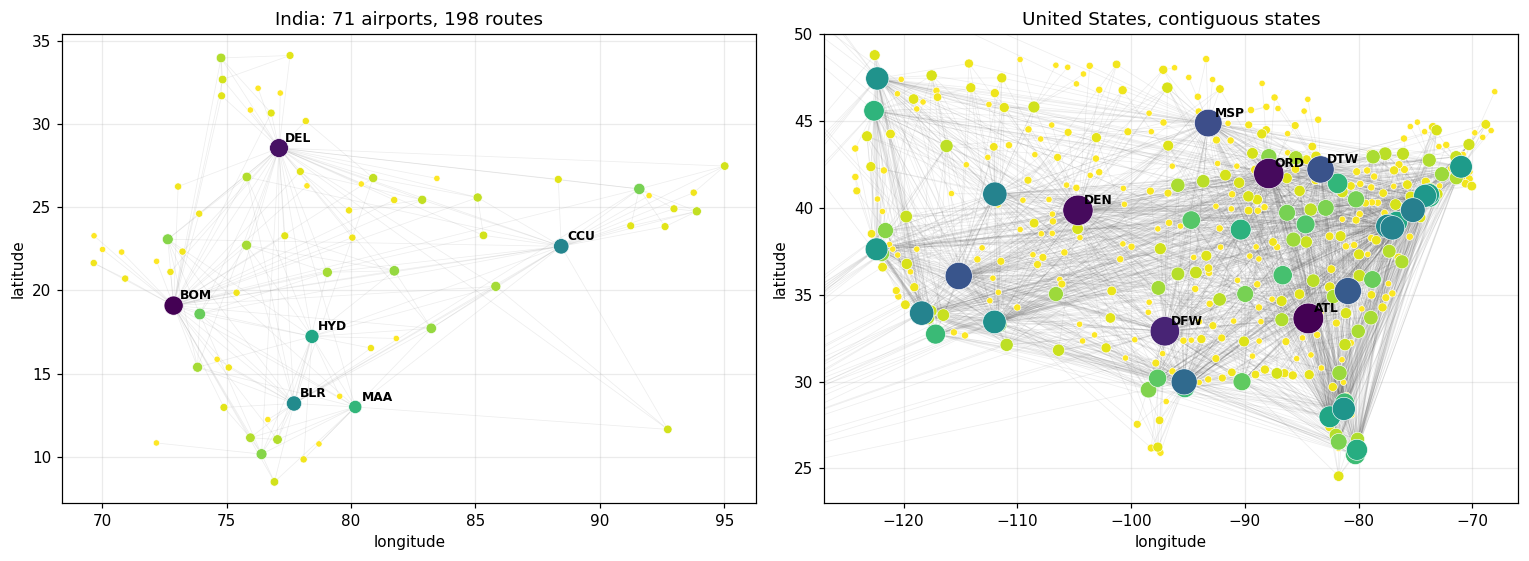

In [3]:
def draw(ax, g, title, extent=None):
    pos = {n: (g.nodes[n]["lon"], g.nodes[n]["lat"]) for n in g}
    for u, v in g.edges():
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#555", alpha=0.10, lw=0.5, zorder=1)
    dg = dict(g.degree()); order = sorted(g.nodes, key=lambda n: dg[n])
    ax.scatter([pos[n][0] for n in order], [pos[n][1] for n in order], s=[10 + 7 * dg[n] ** 0.8 for n in order], c=[dg[n] for n in order], cmap="viridis_r", edgecolor="white", linewidth=0.4, zorder=2)
    for n in sorted(g.nodes, key=lambda n: -dg[n])[:6]: ax.annotate(n, pos[n], xytext=(4, 4), textcoords="offset points", fontsize=8, weight="bold")
    if extent: ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
draw(axes[0], nets["India"], f"India: {nets['India'].number_of_nodes()} airports, {nets['India'].number_of_edges()} routes")
draw(axes[1], nets["United States"], "United States, contiguous states", extent=(-127, -66, 23, 50))
plt.tight_layout(); plt.show()

India's network is small and strongly radial: a handful of large hubs (BOM, DEL and a few more) with a ring of small airports. We now measure how that differs from the US and from the other countries.

## Part B. Structure

We compute, for every network, the quantities of M1 and M2: mean degree, the biggest hub, **hub dominance** (the fraction of all other airports the biggest hub connects to directly, k_max / (N - 1)), the share of airports with a single connection, the inequality of degrees (Gini), clustering, path length, diameter and degree assortativity. The profile function also computes the heavy-tail fit, communities, attacks and both cascade models (Parts C to E); it takes a few minutes.

In [4]:
t0 = time.time()
profiles = {}
for c in domestic:
    g = nets[c]
    profiles[c] = rg.profile(g, seed=1, n_boot=100, n_null=15, n_random=60, thresholds=True, loadcascade=True, all_origins=True)
print(f"{len(domestic)} domestic networks profiled in {time.time() - t0:.0f} s")
t0 = time.time()
profiles["Europe (international)"] = rg.profile(europe, seed=1, n_boot=60, n_null=5, n_random=30, thresholds=True, loadcascade=True, all_origins=True)
profiles["World (international)"] = rg.profile(world, seed=1, n_boot=50, n_null=3, n_random=10, thresholds=True, loadcascade=False, all_origins=False)
print(f"Europe and world profiled in {time.time() - t0:.0f} s")
P = pd.DataFrame(profiles).T
for col in P.columns:
    try: P[col] = pd.to_numeric(P[col])
    except (ValueError, TypeError): pass
dom = P.loc[domestic]

24 domestic networks profiled in 111 s


Europe and world profiled in 92 s


In [5]:
cols = ["airports", "mean degree", "largest hub", "largest degree", "hub dominance (kmax/(N-1))", "share of degree-1 airports", "degree Gini", "clustering C", "path length L", "diameter", "assortativity"]
st = P[cols].copy(); st.columns = ["airports", "mean degree", "hub", "hub degree", "hub dominance", "share degree-1", "degree Gini", "clustering", "path length", "diameter", "assortativity"]
st.style.format({"mean degree": "{:.1f}", "hub dominance": "{:.2f}", "share degree-1": "{:.2f}", "degree Gini": "{:.2f}", "clustering": "{:.2f}", "path length": "{:.2f}", "assortativity": "{:+.2f}"})

,airports,mean degree,hub,hub degree,hub dominance,share degree-1,degree Gini,clustering,path length,diameter,assortativity
United States,541,10.3,ATL,153,0.28,0.28,0.72,0.49,3.20,7,-0.34
Canada,204,4.3,YVR,34,0.17,0.14,0.45,0.45,4.12,12,-0.10
China,175,15.6,PEK,110,0.63,0.11,0.61,0.66,2.20,4,-0.45
Brazil,124,6.0,VCP,50,0.41,0.26,0.58,0.41,3.00,8,-0.26
Australia,113,4.0,SYD,45,0.40,0.27,0.54,0.47,2.99,8,-0.34
Russia,112,6.3,DME,70,0.63,0.29,0.58,0.40,2.43,5,-0.40
India,71,5.6,BOM,45,0.64,0.24,0.56,0.62,2.24,4,-0.47
Indonesia,64,4.7,CGK,31,0.49,0.25,0.52,0.48,2.61,5,-0.30
Japan,62,5.6,HND,49,0.80,0.29,0.57,0.44,2.09,4,-0.52
Mexico,56,5.8,MEX,51,0.93,0.29,0.57,0.56,1.95,3,-0.58


### B1. Is the US typical? Where does it fall among the 24 domestic networks?

In [6]:
us = dom.loc["United States"]
def rank_row(col, higher_is="higher"):
    r = dom[col].rank(ascending=False, method="min")
    return int(r["United States"])
rows = []
for col, nice in [("mean degree", "mean degree"), ("hub dominance (kmax/(N-1))", "hub dominance"), ("share of degree-1 airports", "share of degree-1 airports"), ("degree Gini", "degree inequality (Gini)"),
                  ("clustering C", "clustering"), ("path length L", "path length"), ("diameter", "diameter"), ("assortativity", "degree assortativity")]:
    rows.append({"quantity": nice, "United States": us[col], "median of the 24": dom[col].median(), "min": dom[col].min(), "max": dom[col].max(), "US rank (1 = highest of 24)": rank_row(col)})
display(pd.DataFrame(rows).style.hide(axis="index").format({"United States": "{:.2f}", "median of the 24": "{:.2f}", "min": "{:.2f}", "max": "{:.2f}"}))

quantity,United States,median of the 24,min,max,US rank (1 = highest of 24)
mean degree,10.28,5.24,3.00,15.57,2
hub dominance,0.28,0.69,0.17,0.97,23
share of degree-1 airports,0.28,0.28,0.03,0.53,11
degree inequality (Gini),0.72,0.54,0.34,0.72,1
clustering,0.49,0.46,0.21,0.66,7
path length,3.20,2.23,1.86,4.12,2
diameter,7.00,4.00,3.00,12.00,4
degree assortativity,-0.34,-0.45,-0.81,-0.10,6


**Reading this.** The US is **atypical in several ways** compared with the other 23 domestic networks:
- It has the **highest inequality of degrees** (Gini 0.72, rank 1), the second-highest mean degree and the second-longest paths (after Canada), because it is by far the largest network.
- It has one of the **lowest hub dominance** values (rank 23 of 24): ATL connects to 28% of the other airports, whereas in the median country the top hub connects to **69%** (in Mexico, Argentina, Turkey, Greece and the Philippines the top hub reaches almost 90% or more). So the paper's picture of a hub-dominated network describes the US only moderately well compared with elsewhere.
- It is typical in its share of single-connection airports (28%, the median) and in its **negative degree assortativity** (hubs link to small airports), which holds in **all 24** countries (from -0.10 to -0.81).

### B2. The paper's "k_max ~ N" claim
In M2 we noted that the paper's anomalous-regime reading ("the biggest hub grows linearly with the size of the network") cannot be tested on one network. With 24 countries it can: if k_max grows linearly with N, the log-log slope is 1.

k_max ~ N^0.58  (95% bootstrap interval 0.29 to 0.81, R2 = 0.69) over 24 domestic networks
hub dominance (k_max / (N - 1)) vs N: Spearman -0.58


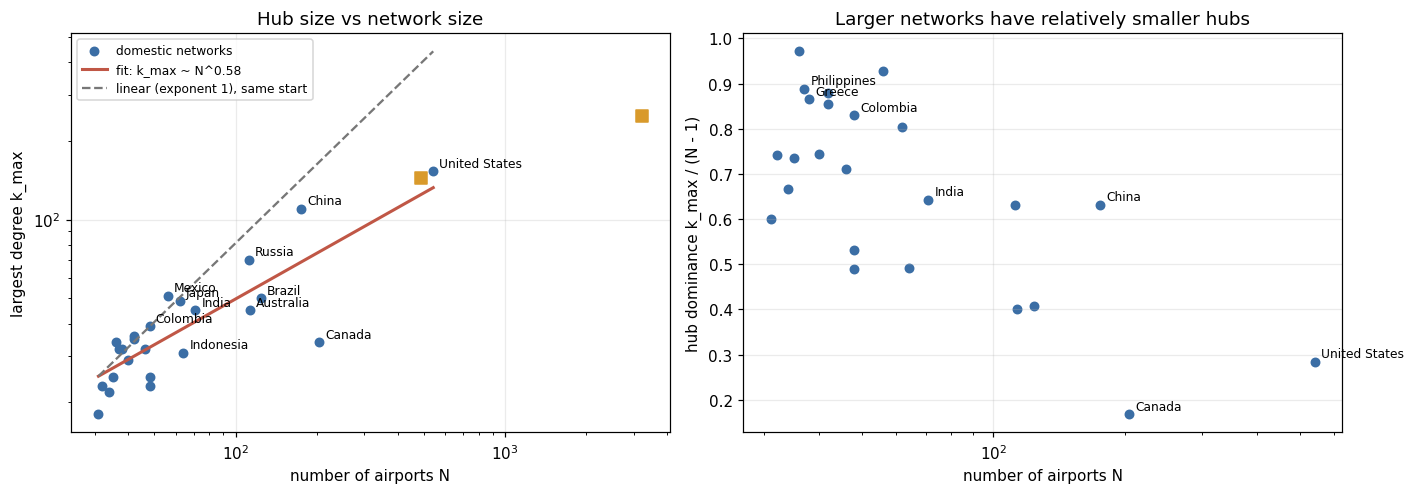

In [7]:
x = np.log(dom["airports"].astype(float)); y = np.log(dom["largest degree"].astype(float))
slope, icpt = np.polyfit(x, y, 1)
boots = []
for _ in range(2000):
    i = rng.integers(0, len(x), len(x)); boots.append(np.polyfit(x.values[i], y.values[i], 1)[0])
lo, hi = np.percentile(boots, [2.5, 97.5]); r2 = np.corrcoef(x, y)[0, 1] ** 2
print(f"k_max ~ N^{slope:.2f}  (95% bootstrap interval {lo:.2f} to {hi:.2f}, R2 = {r2:.2f}) over {len(dom)} domestic networks")
print(f"hub dominance (k_max / (N - 1)) vs N: Spearman {spearmanr(dom['airports'], dom['hub dominance (kmax/(N-1))']).statistic:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.scatter(dom["airports"], dom["largest degree"], s=30, color=BLUE, label="domestic networks")
for c in domestic:
    if c in ("United States", "India", "China", "Canada", "Brazil", "Australia", "Russia", "Mexico", "Japan", "Colombia", "Indonesia"): ax.annotate(c, (dom.loc[c, "airports"], dom.loc[c, "largest degree"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
xs = np.array([dom["airports"].min(), dom["airports"].max()]); ax.plot(xs, np.exp(icpt) * xs ** slope, color=RED, lw=2, label=f"fit: k_max ~ N^{slope:.2f}")
ax.plot(xs, np.exp(icpt) * xs[0] ** (slope - 1) * xs, color=GREY, ls="--", label="linear (exponent 1), same start")
for nm_ in ("Europe (international)", "World (international)"): ax.scatter(P.loc[nm_, "airports"], P.loc[nm_, "largest degree"], s=60, marker="s", color=ORANGE)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("number of airports N"); ax.set_ylabel("largest degree k_max"); ax.set_title("Hub size vs network size"); ax.legend(fontsize=8)
ax = axes[1]
ax.scatter(dom["airports"], dom["hub dominance (kmax/(N-1))"], s=30, color=BLUE)
for c in ("United States", "India", "China", "Canada", "Colombia", "Greece", "Philippines"): ax.annotate(c, (dom.loc[c, "airports"], dom.loc[c, "hub dominance (kmax/(N-1))"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("number of airports N"); ax.set_ylabel("hub dominance k_max / (N - 1)"); ax.set_title("Larger networks have relatively smaller hubs")
plt.tight_layout(); plt.show()

**Reading this.** The biggest hub grows **much more slowly than linearly** with network size: the fitted exponent is 0.58 (95% bootstrap interval 0.29 to 0.81), which excludes 1. A network ten times larger has a biggest hub only about four times larger, so the relative dominance of the biggest hub *falls* as networks grow (right panel). The paper's reading of its gamma value ("the biggest hub's degree grows linearly with the size of the network", k_max ~ N) is therefore **not supported by cross-country data**, which strengthens the M2 conclusion that the "anomalous regime" label is not established. (The world network, an orange square, has a hub of 248 connections in 3,231 airports, far below the linear line.)

## Part C. Heavy tails and communities

### C1. Is a pure power law rejected elsewhere too?

pure power law rejected in 5 of 24 domestic networks; world: p = 0.000, Europe: p = 0.000
rejected among the 8 largest networks: 2 of 8; among the 8 smallest: 1 of 8
discrete gamma: median 2.41, range 1.73 to 4.08; share with gamma at most 2: 17%


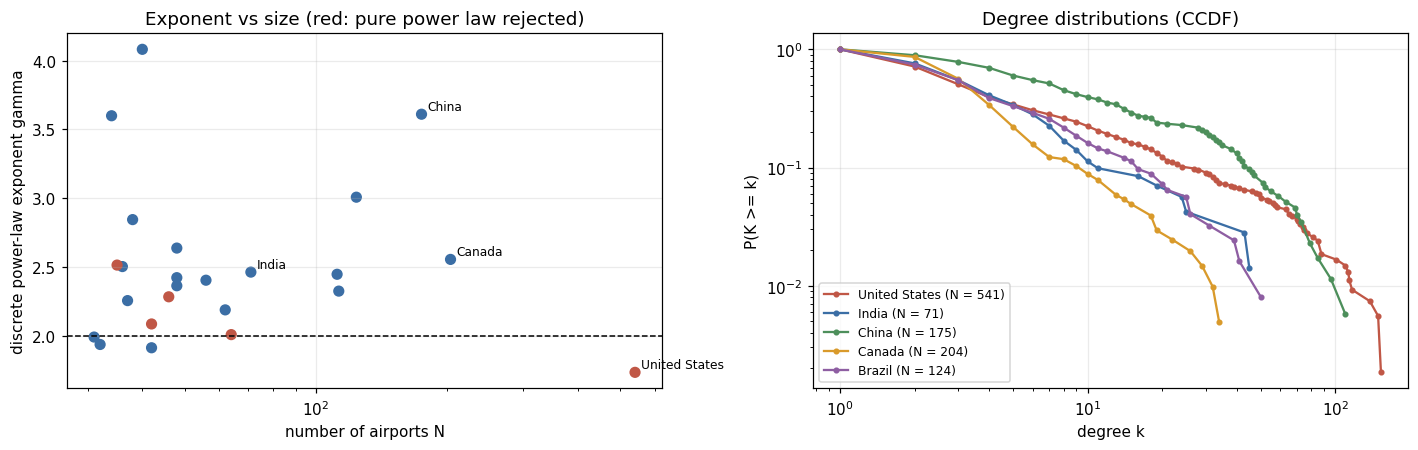

,airports,gamma (discrete MLE),gamma x_min,power-law GOF p,power law rejected (p < 0.1)
United States,541,1.73,2,0.000,yes
Canada,204,2.55,3,0.700,no
China,175,3.61,38,0.470,no
Brazil,124,3.01,15,0.210,no
Australia,113,2.32,2,0.360,no
Russia,112,2.45,8,0.550,no
India,71,2.46,6,0.880,no
Indonesia,64,2.01,2,0.040,yes
Japan,62,2.19,4,0.580,no
Mexico,56,2.40,4,0.420,no


In [8]:
ht = dom[["airports", "gamma (discrete MLE)", "gamma x_min", "power-law GOF p"]].copy()
ht["power law rejected (p < 0.1)"] = np.where(ht["power-law GOF p"] < 0.1, "yes", "no")
n_rej = int((ht["power-law GOF p"] < 0.1).sum())
print(f"pure power law rejected in {n_rej} of {len(ht)} domestic networks; world: p = {P.loc['World (international)', 'power-law GOF p']:.3f}, Europe: p = {P.loc['Europe (international)', 'power-law GOF p']:.3f}")
print(f"rejected among the 8 largest networks: {int((ht['power-law GOF p'].iloc[:8] < 0.1).sum())} of 8; among the 8 smallest: {int((ht['power-law GOF p'].iloc[-8:] < 0.1).sum())} of 8")
print(f"discrete gamma: median {ht['gamma (discrete MLE)'].median():.2f}, range {ht['gamma (discrete MLE)'].min():.2f} to {ht['gamma (discrete MLE)'].max():.2f}; share with gamma at most 2: {(ht['gamma (discrete MLE)'] <= 2).mean():.0%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]; ax.scatter(ht["airports"], ht["gamma (discrete MLE)"], c=np.where(ht["power-law GOF p"] < 0.1, RED, BLUE), s=40)
ax.axhline(2, color="black", ls="--", lw=1); ax.set_xscale("log"); ax.set_xlabel("number of airports N"); ax.set_ylabel("discrete power-law exponent gamma")
ax.set_title("Exponent vs size (red: pure power law rejected)")
for c in ("United States", "India", "China", "Canada"): ax.annotate(c, (ht.loc[c, "airports"], ht.loc[c, "gamma (discrete MLE)"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax = axes[1]
for c, col in [("United States", RED), ("India", BLUE), ("China", GREEN), ("Canada", ORANGE), ("Brazil", PURPLE)]:
    d = np.array([v for _, v in nets[c].degree()]); ks = np.sort(np.unique(d)); ax.loglog(ks, [(d >= k).mean() for k in ks], "o-", ms=3, color=col, label=f"{c} (N = {len(d)})")
ax.set_xlabel("degree k"); ax.set_ylabel("P(K >= k)"); ax.set_title("Degree distributions (CCDF)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
ht.style.format({"gamma (discrete MLE)": "{:.2f}", "power-law GOF p": "{:.3f}"})

**Reading this.** The M2 result for the US is **the extreme case, not the rule**:
- A pure power law is rejected in only **5 of 24** domestic networks (the US, Indonesia, France, Turkey, Sweden); the large networks Canada, China, Brazil, Australia and Russia are *not* rejected. So the degree distributions of most countries are statistically compatible with a power law (small networks also have little power to reject).
- But the **exponents are very different**: the median discrete gamma is 2.4, the US has the **lowest** (1.73), and only 4 of 24 countries (17%) have gamma at most 2, the "anomalous regime". The paper's gamma below 2 is therefore a **US-specific** feature, not a signature of airport networks in general.
- Fits in China (x_min = 38) and Spain (x_min = 12) use only a small tail, so their exponents are loosely determined.

### C2. Communities
M3 and M4 found that the US has strong community structure that degrees do not explain. We compare each network's Louvain modularity with the modularity of degree-preserving random networks (z-score).

In [9]:
cm_ = dom[["airports", "Louvain modularity", "modularity z vs degree-preserving null"]].copy()
print(f"modularity z-score above 3 (communities stronger than degrees explain) in {int((cm_['modularity z vs degree-preserving null'] > 3).sum())} of {len(cm_)} domestic networks; median z = {cm_['modularity z vs degree-preserving null'].median():.1f}")
print(f"Louvain modularity: United States {cm_.loc['United States', 'Louvain modularity']:.2f}, India {cm_.loc['India', 'Louvain modularity']:.2f}, median {cm_['Louvain modularity'].median():.2f}; world {P.loc['World (international)', 'Louvain modularity']:.2f}, Europe {P.loc['Europe (international)', 'Louvain modularity']:.2f}")
cm_.style.format({"Louvain modularity": "{:.2f}", "modularity z vs degree-preserving null": "{:.1f}"})

modularity z-score above 3 (communities stronger than degrees explain) in 12 of 24 domestic networks; median z = 3.2
Louvain modularity: United States 0.35, India 0.34, median 0.32; world 0.66, Europe 0.26


,airports,Louvain modularity,modularity z vs degree-preserving null
United States,541,0.35,61.0
Canada,204,0.68,32.4
China,175,0.17,14.3
Brazil,124,0.37,11.6
Australia,113,0.47,8.7
Russia,112,0.33,7.7
India,71,0.34,13.5
Indonesia,64,0.42,10.8
Japan,62,0.25,1.5
Mexico,56,0.23,3.7


**Reading this.** Community structure stronger than the degree sequence explains (z above 3) is found in **12 of the 24** domestic networks (median z about 3), not in all of them: it is clear in the larger networks (the US z = 61, Canada 32, Norway 15, China 14, India 13.5, Brazil 12, Indonesia 11, Australia 9, Russia 8) and absent in several of the smallest (Turkey, Sweden and Thailand have z at or below 0; Colombia, France, Spain, Italy, Argentina below 1). The world network has a high modularity (0.66, continents), Europe a lower one (0.26). So the M3 and M4 conclusion (geography creates communities beyond what hubs explain) is a feature of large, geographically extended networks; in small, hub-dominated ones the hub structure alone explains the modularity.

## Part D. Attacks: random versus targeted
The paper's central message (M5) is "robust to random failure, fragile to targeted attack". For each network we measure the fraction of airports that must be removed to halve the largest component, under random removal and under static degree and betweenness attacks.

targeted attack halves the LCC with fewer than half the removals of random failure in 23 of 24 domestic networks (ratio median 0.20, min 0.07, max 0.59)
United States: random 0.35 of the airports, degree attack 0.065, betweenness attack 0.035
India: random 0.41, degree attack 0.056, betweenness attack 0.056


,airports,random,degree attack,betweenness attack,survivors connected after top hub removed,... after top 3 removed,LCC share after top 5% removed (betweenness),targeted / random (best attack)
United States,541,0.35,0.065,0.035,0.84,0.79,0.40,0.10
Canada,204,0.32,0.059,0.054,1.00,0.99,0.51,0.17
China,175,0.46,0.149,0.131,1.00,0.98,0.83,0.29
Brazil,124,0.38,0.089,0.081,0.97,0.86,0.73,0.21
Australia,113,0.35,0.053,0.053,0.89,0.76,0.40,0.15
Russia,112,0.40,0.080,0.089,0.93,0.83,0.65,0.20
India,71,0.41,0.056,0.056,0.90,0.59,0.34,0.14
Indonesia,64,0.39,0.094,0.094,0.97,0.87,0.83,0.24
Japan,62,0.42,0.081,0.081,0.74,0.61,0.58,0.19
Mexico,56,0.41,0.089,0.071,0.73,0.58,0.55,0.17


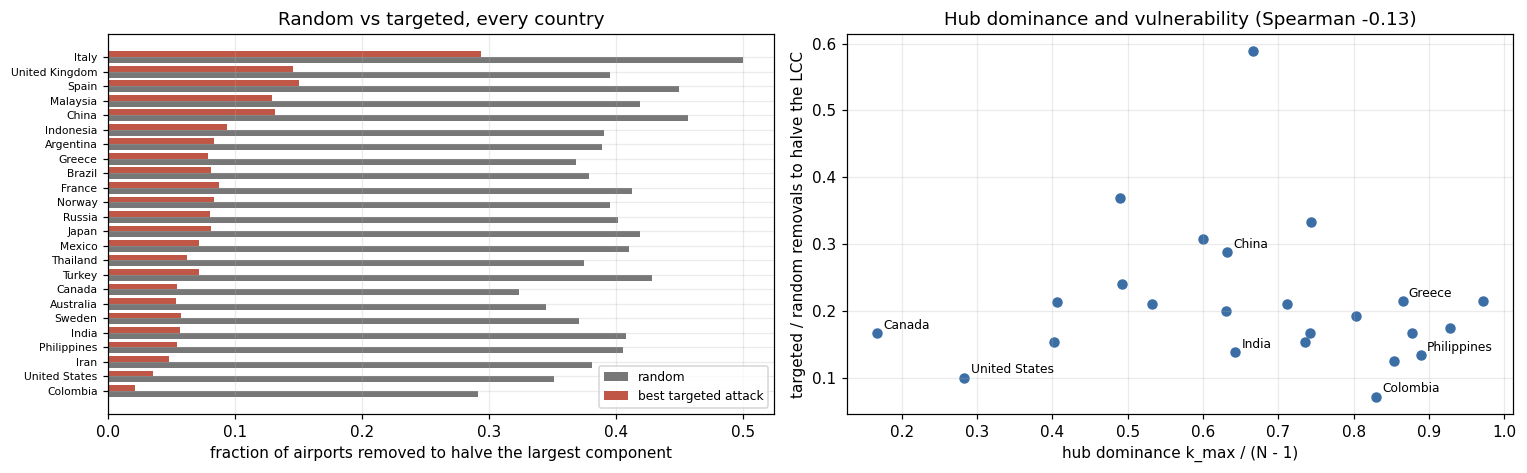

In [10]:
att = dom[["airports", "random: removals to halve LCC / N", "degree attack: removals to halve LCC / N", "betweenness attack: removals to halve LCC / N", "LCC / survivors after removing the top hub (betweenness)",
           "LCC / survivors after removing the top 3 (betweenness)", "LCC share after removing top 5% by betweenness"]].copy()
att.columns = ["airports", "random", "degree attack", "betweenness attack", "survivors connected after top hub removed", "... after top 3 removed", "LCC share after top 5% removed (betweenness)"]
att["targeted / random (best attack)"] = att[["degree attack", "betweenness attack"]].min(axis=1) / att["random"]
n_ok = int((att["targeted / random (best attack)"] < 0.5).sum())
print(f"targeted attack halves the LCC with fewer than half the removals of random failure in {n_ok} of {len(att)} domestic networks (ratio median {att['targeted / random (best attack)'].median():.2f}, min {att['targeted / random (best attack)'].min():.2f}, max {att['targeted / random (best attack)'].max():.2f})")
print(f"United States: random {att.loc['United States', 'random']:.2f} of the airports, degree attack {att.loc['United States', 'degree attack']:.3f}, betweenness attack {att.loc['United States', 'betweenness attack']:.3f}")
print(f"India: random {att.loc['India', 'random']:.2f}, degree attack {att.loc['India', 'degree attack']:.3f}, betweenness attack {att.loc['India', 'betweenness attack']:.3f}")
display(att.style.format({"random": "{:.2f}", "degree attack": "{:.3f}", "betweenness attack": "{:.3f}", "survivors connected after top hub removed": "{:.2f}", "... after top 3 removed": "{:.2f}", "LCC share after top 5% removed (betweenness)": "{:.2f}", "targeted / random (best attack)": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
order = att.sort_values("targeted / random (best attack)").index
ax = axes[0]; yy = np.arange(len(order))
ax.barh(yy - 0.2, att.loc[order, "random"], 0.4, color=GREY, label="random"); ax.barh(yy + 0.2, att.loc[order, ["degree attack", "betweenness attack"]].min(axis=1), 0.4, color=RED, label="best targeted attack")
ax.set_yticks(yy); ax.set_yticklabels(order, fontsize=7); ax.set_xlabel("fraction of airports removed to halve the largest component"); ax.set_title("Random vs targeted, every country"); ax.legend(fontsize=8)
ax = axes[1]; ax.scatter(dom["hub dominance (kmax/(N-1))"], att["targeted / random (best attack)"], s=34, color=BLUE)
for c in ("United States", "India", "China", "Colombia", "Greece", "Philippines", "Canada"): ax.annotate(c, (dom.loc[c, "hub dominance (kmax/(N-1))"], att.loc[c, "targeted / random (best attack)"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("hub dominance k_max / (N - 1)"); ax.set_ylabel("targeted / random removals to halve the LCC"); ax.set_title(f"Hub dominance and vulnerability (Spearman {spearmanr(dom['hub dominance (kmax/(N-1))'], att['targeted / random (best attack)']).statistic:+.2f})")
plt.tight_layout(); plt.show()

**Reading this.** "Robust to random failure, fragile to targeted attack" is a **near-universal property** of these networks: in 23 of the 24 countries a targeted attack halves the largest component with less than half of the removals random failure needs (the last column is below 0.5; the exception is Italy at 0.59, a small and densely connected network with several comparable hubs). The ratio is typically about 0.2; the US (0.10) is among the strongest cases, India is 0.14, and Colombia (0.06) is the most extreme. So the paper's qualitative conclusion is not specific to the US. How *large* the gap is varies, and countries with a more dominant hub tend to lose connectivity when that hub goes (the survivors-connected columns).

## Part E. Cascades
### E1. The threshold cascade (M6) and the load cascade (M9) in every country
For each network we record the **critical threshold of the biggest hub** and of the **worst origin** in the threshold model, the **share of origins that can collapse the network at threshold 0.10**, and in the load model the **critical spare capacity alpha\*** and the share of origins that can collapse the network with no spare capacity.

In [11]:
cc = P.loc[domestic + ["Europe (international)"], ["airports", "threshold cascade: critical threshold of the top hub", "threshold cascade: worst-origin critical threshold", "threshold cascade: worst origin",
        "threshold cascade: share of origins causing an avalanche at t = 0.10", "load cascade: critical spare capacity alpha*", "load cascade: share of origins causing an avalanche at alpha = 0", "load cascade: most dangerous origin"]].copy()
cc.columns = ["airports", "threshold: hub t_c", "threshold: worst t_c", "worst origin (threshold)", "threshold: % origins dangerous at t=0.10", "load: alpha*", "load: % origins dangerous at alpha=0", "most dangerous origin (load)"]
for c in ("threshold: % origins dangerous at t=0.10", "load: % origins dangerous at alpha=0"): cc[c] = (100 * pd.to_numeric(cc[c])).round(1)
display(cc.style.format({"threshold: hub t_c": "{:.3f}", "threshold: worst t_c": "{:.3f}", "load: alpha*": "{:.2f}"}))
w = P.loc["World (international)"]
print(f"world network (hub origin only): threshold-model critical threshold of the top hub {w['threshold cascade: critical threshold of the top hub']:.3f} (the biggest hub is {w['largest hub']})")
d_ = dom
print(f"threshold model, worst-origin critical threshold: median {d_['threshold cascade: worst-origin critical threshold'].median():.3f} (US {d_.loc['United States', 'threshold cascade: worst-origin critical threshold']:.3f}, India {d_.loc['India', 'threshold cascade: worst-origin critical threshold']:.3f}); load model alpha*: median {d_['load cascade: critical spare capacity alpha*'].median():.2f} (US {d_.loc['United States', 'load cascade: critical spare capacity alpha*']:.2f}, India {d_.loc['India', 'load cascade: critical spare capacity alpha*']:.2f})")
print(f"Spearman between the two models' fragility across the 24 networks: threshold-share vs load-share(alpha=0) = {spearmanr(d_['threshold cascade: share of origins causing an avalanche at t = 0.10'], d_['load cascade: share of origins causing an avalanche at alpha = 0']).statistic:+.2f};  worst t_c vs alpha* = {spearmanr(d_['threshold cascade: worst-origin critical threshold'], d_['load cascade: critical spare capacity alpha*']).statistic:+.2f}")

,airports,threshold: hub t_c,threshold: worst t_c,worst origin (threshold),threshold: % origins dangerous at t=0.10,load: alpha*,load: % origins dangerous at alpha=0,most dangerous origin (load)
United States,541,0.165,0.200,LAS,7.400000,0.20,7.400000,ORD
Canada,204,0.310,0.310,YVR,80.400000,0.35,18.100000,YOW
China,175,0.200,0.200,PEK,16.000000,0.20,22.300000,CAN
Brazil,124,0.250,0.250,BSB,50.800000,0.50,13.700000,VCP
Australia,113,0.330,0.330,SYD,50.400000,0.30,6.200000,BNE
Russia,112,0.280,0.280,DME,52.700000,0.75,9.800000,DME
India,71,0.330,0.330,BOM,50.700000,0.20,7.000000,BOM
Indonesia,64,0.330,0.330,CGK,75.000000,0.30,7.800000,CGK
Japan,62,0.330,0.330,HND,41.900000,0.40,9.700000,HND
Mexico,56,0.330,0.330,MEX,42.900000,0.35,8.900000,MEX


world network (hub origin only): threshold-model critical threshold of the top hub 0.140 (the biggest hub is AMS)
threshold model, worst-origin critical threshold: median 0.330 (US 0.200, India 0.330); load model alpha*: median 0.30 (US 0.20, India 0.20)
Spearman between the two models' fragility across the 24 networks: threshold-share vs load-share(alpha=0) = +0.27;  worst t_c vs alpha* = +0.30


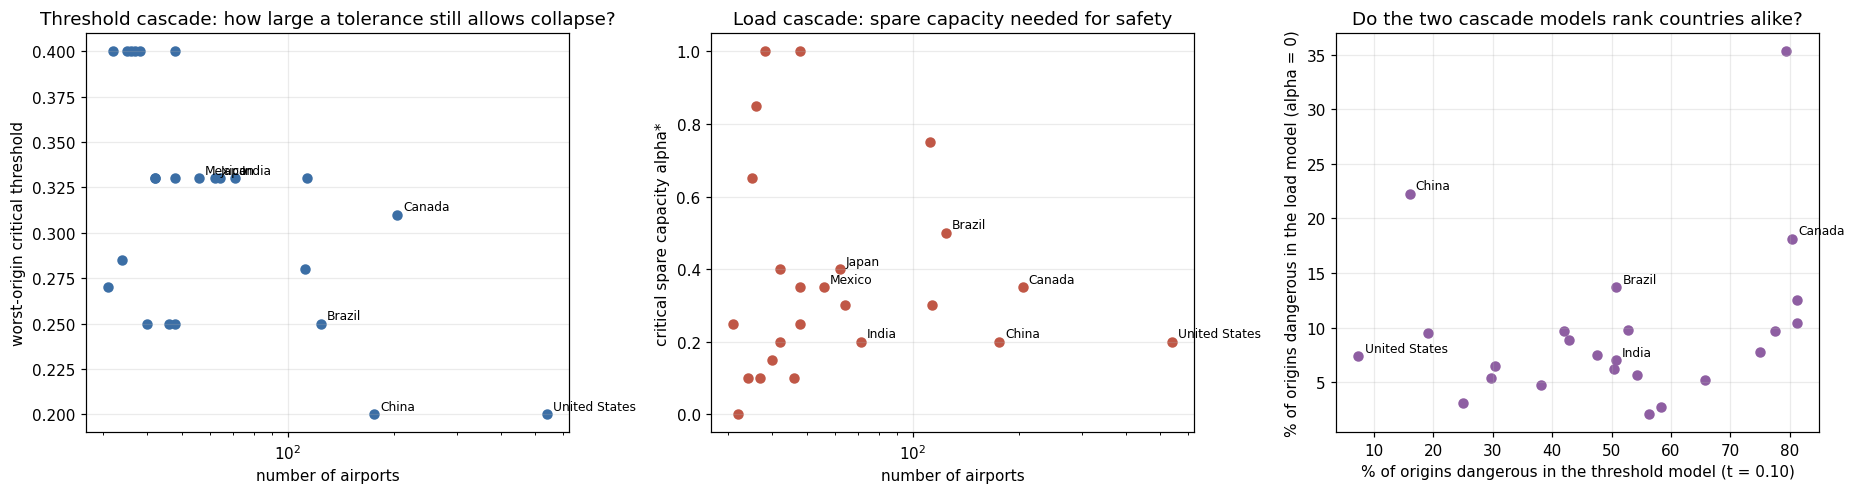

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]; ax.scatter(dom["airports"], dom["threshold cascade: worst-origin critical threshold"], s=34, color=BLUE)
for c in ("United States", "India", "China", "Canada", "Brazil", "Mexico", "Japan"): ax.annotate(c, (dom.loc[c, "airports"], dom.loc[c, "threshold cascade: worst-origin critical threshold"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("number of airports"); ax.set_ylabel("worst-origin critical threshold"); ax.set_title("Threshold cascade: how large a tolerance still allows collapse?")
ax = axes[1]; ax.scatter(dom["airports"], dom["load cascade: critical spare capacity alpha*"], s=34, color=RED)
for c in ("United States", "India", "China", "Canada", "Brazil", "Mexico", "Japan"): ax.annotate(c, (dom.loc[c, "airports"], dom.loc[c, "load cascade: critical spare capacity alpha*"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("number of airports"); ax.set_ylabel("critical spare capacity alpha*"); ax.set_title("Load cascade: spare capacity needed for safety")
ax = axes[2]; ax.scatter(100 * dom["threshold cascade: share of origins causing an avalanche at t = 0.10"], 100 * dom["load cascade: share of origins causing an avalanche at alpha = 0"], s=34, color=PURPLE)
for c in ("United States", "India", "China", "Canada", "Brazil"): ax.annotate(c, (100 * dom.loc[c, "threshold cascade: share of origins causing an avalanche at t = 0.10"], 100 * dom.loc[c, "load cascade: share of origins causing an avalanche at alpha = 0"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("% of origins dangerous in the threshold model (t = 0.10)"); ax.set_ylabel("% of origins dangerous in the load model (alpha = 0)"); ax.set_title("Do the two cascade models rank countries alike?")
plt.tight_layout(); plt.show()

**Reading this.** The two cascade models give **different pictures of which countries are fragile**:
- In the **threshold** model, most countries are far more cascade-prone than the US: the worst-origin critical threshold is 0.33 in the median country against 0.20 in the US, and a majority of single failures can collapse many of them at threshold 0.10 (Canada 80%, UK 81%, Norway 81%, Italy 79%, Malaysia 77%, Indonesia 75%, against 7% in the US and 16% in China). Canada, with 204 airports, is as cascade-prone as countries a third of its size, so **size is not the explanation**; Part F shows that the explanation is sparsity.
- In the **load** model the critical spare capacity **varies a great deal** (from 0 in Thailand to 1.0 in Colombia and Greece, median 0.30) and the US (0.20) is at the low end: in this sense the US is *safer* than most countries. The share of origins that can collapse the network with no spare capacity is a few percent in most countries (US 7.4%, India 7.0%), but 22% in China, 35% in Italy and 38% in Europe.
- The two measures are only weakly related across countries (Spearman +0.27 and +0.30, printed above), so a ranking of countries by "fragility" depends on the cascade model, in line with M9.

## Part F. What explains fragility across countries?
We correlate (Spearman, 24 networks) several fragility measures with structural properties. This is exploratory, with 24 points: we report which relations are strong enough to be worth believing.

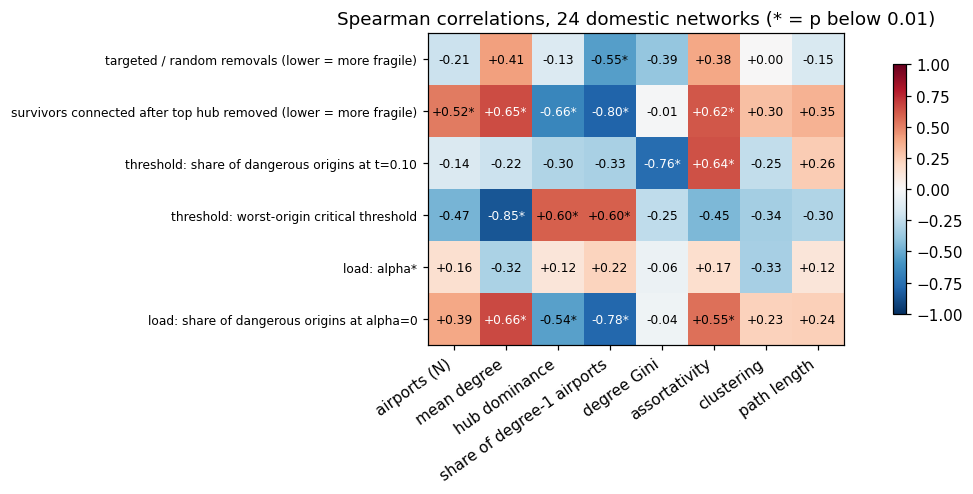

,airports (N),mean degree,hub dominance,share of degree-1 airports,degree Gini,assortativity,clustering,path length
targeted / random removals (lower = more fragile),-0.21,+0.41*,-0.13,-0.55**,-0.39,+0.38,+0.00,-0.15
survivors connected after top hub removed (lower = more fragile),+0.52**,+0.65**,-0.66**,-0.80**,-0.01,+0.62**,+0.30,+0.35
threshold: share of dangerous origins at t=0.10,-0.14,-0.22,-0.30,-0.33,-0.76**,+0.64**,-0.25,+0.26
threshold: worst-origin critical threshold,-0.47*,-0.85**,+0.60**,+0.60**,-0.25,-0.45*,-0.34,-0.30
load: alpha*,+0.16,-0.32,+0.12,+0.22,-0.06,+0.17,-0.33,+0.12
load: share of dangerous origins at alpha=0,+0.39,+0.66**,-0.54**,-0.78**,-0.04,+0.55**,+0.23,+0.24


(** p below 0.01, * p below 0.05)
hub dominance vs share of survivors connected after the top hub is removed: Spearman -0.66
mean degree vs threshold-model share of dangerous origins: -0.22; N vs the same: -0.14


In [13]:
frag = pd.DataFrame({
    "targeted / random removals (lower = more fragile)": att["targeted / random (best attack)"],
    "survivors connected after top hub removed (lower = more fragile)": att["survivors connected after top hub removed"],
    "threshold: share of dangerous origins at t=0.10": dom["threshold cascade: share of origins causing an avalanche at t = 0.10"],
    "threshold: worst-origin critical threshold": dom["threshold cascade: worst-origin critical threshold"],
    "load: alpha*": dom["load cascade: critical spare capacity alpha*"],
    "load: share of dangerous origins at alpha=0": dom["load cascade: share of origins causing an avalanche at alpha = 0"]})
struct = pd.DataFrame({"airports (N)": dom["airports"], "mean degree": dom["mean degree"], "hub dominance": dom["hub dominance (kmax/(N-1))"], "share of degree-1 airports": dom["share of degree-1 airports"],
                       "degree Gini": dom["degree Gini"], "assortativity": dom["assortativity"], "clustering": dom["clustering C"], "path length": dom["path length L"]})
rho = pd.DataFrame(index=frag.columns, columns=struct.columns, dtype=float); pv = rho.copy()
for a in frag.columns:
    for b in struct.columns:
        r = spearmanr(frag[a], struct[b]); rho.loc[a, b] = r.statistic; pv.loc[a, b] = r.pvalue
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(rho.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(struct.columns))); ax.set_xticklabels(struct.columns, rotation=35, ha="right"); ax.set_yticks(range(len(frag.columns))); ax.set_yticklabels(frag.columns, fontsize=8)
for i in range(rho.shape[0]):
    for j in range(rho.shape[1]):
        ax.text(j, i, f"{rho.values[i, j]:+.2f}" + ("*" if pv.values[i, j] < 0.01 else ""), ha="center", va="center", fontsize=8, color="white" if abs(rho.values[i, j]) > 0.6 else "black")
ax.set_title("Spearman correlations, 24 domestic networks (* = p below 0.01)"); ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
tab_rho = rho.copy().astype(float)
tab_rho = tab_rho.map(lambda v: f"{v:+.2f}")
for a in frag.columns:
    for b in struct.columns:
        p_ = pv.loc[a, b]; tab_rho.loc[a, b] += "**" if p_ < 0.01 else ("*" if p_ < 0.05 else "")
display(tab_rho)
print("(** p below 0.01, * p below 0.05)")
print(f"hub dominance vs share of survivors connected after the top hub is removed: Spearman {spearmanr(dom['hub dominance (kmax/(N-1))'], att['survivors connected after top hub removed']).statistic:+.2f}")
print(f"mean degree vs threshold-model share of dangerous origins: {spearmanr(dom['mean degree'], dom['threshold cascade: share of origins causing an avalanche at t = 0.10']).statistic:+.2f}; N vs the same: {spearmanr(dom['airports'], dom['threshold cascade: share of origins causing an avalanche at t = 0.10']).statistic:+.2f}")

**Reading this.** The table above gives the correlations (Spearman, 24 networks; ** p below 0.01, * p below 0.05). The main patterns:
- **Losing the biggest hub:** the share of surviving airports that stay connected after the top hub is removed is lower in networks with a **larger share of degree-1 airports (-0.80)** and with **higher hub dominance (-0.66)**, and higher in denser networks (mean degree +0.65) and larger ones (+0.52). The mechanism is direct: spokes attached only to the dominant hub are stranded when it goes.
- **Targeted attack relative to random:** the targeted-to-random ratio is lower (more fragile) when there are more degree-1 airports (-0.55) and higher degree inequality (-0.39, not significant), and higher in denser networks (mean degree +0.41).
- **Threshold cascade:** the worst-origin critical threshold is strongly **negatively related to mean degree (-0.85)**: sparse networks have higher critical thresholds, i.e. a given airport tolerates a smaller *fraction* of failed neighbours. It is also higher with more hub dominance (+0.60) and more degree-1 airports (+0.60). Size matters much less (-0.47 for the threshold, -0.14 for the share of dangerous origins). The *share* of dangerous origins is related to degree inequality (-0.76) and assortativity (+0.64): networks with more equal degrees and less negative assortativity have more airports that can start a collapse.
- **Load cascade:** the critical spare capacity alpha* is **not significantly related to any** of these properties; the share of origins that can collapse the network at zero spare capacity is *higher* in denser networks (mean degree +0.66) and lower with more degree-1 airports and more hub dominance (-0.78, -0.54).
- **The two cascade models have opposite relations to density**: sparse networks are the most threshold-cascade-prone, dense networks the ones with the most load-cascade-dangerous origins (many mid-sized airports carry substantial through-traffic). This is the cross-country version of M9's finding that the two models identify different weaknesses.
- With 24 networks these are associations, not causes, and the structural properties are themselves intertwined.

## Part G. India in detail
India is the case of interest. We compare it with the **other small and medium countries (30 to 130 airports)**, which is the fair comparison group, and with the US.

In [14]:
small = [c for c in domestic if 30 <= nets[c].number_of_nodes() <= 130]
print(f"comparison group: {len(small)} countries with 30 to 130 airports")
cmp_cols = ["airports", "hub dominance (kmax/(N-1))", "share of degree-1 airports", "assortativity", "clustering C", "path length L", "gamma (discrete MLE)", "power-law GOF p",
            "random: removals to halve LCC / N", "degree attack: removals to halve LCC / N", "LCC / survivors after removing the top hub (betweenness)",
            "threshold cascade: worst-origin critical threshold", "threshold cascade: share of origins causing an avalanche at t = 0.10", "load cascade: critical spare capacity alpha*", "load cascade: share of origins causing an avalanche at alpha = 0"]
ind = P.loc["India", cmp_cols]; us_ = P.loc["United States", cmp_cols]; grp = P.loc[small, cmp_cols]
rows = []
for c in cmp_cols:
    pct = float((grp[c].astype(float) <= float(ind[c])).mean())
    rows.append({"quantity": c, "India": float(ind[c]), "United States": float(us_[c]), "median of the small/medium group": float(grp[c].median()), "India's percentile in the group": f"{pct:.0%}"})
display(pd.DataFrame(rows).style.hide(axis="index").format({"India": "{:.3f}", "United States": "{:.3f}", "median of the small/medium group": "{:.3f}"}))
gi = nets["India"]; dgi = dict(gi.degree())
print("India's largest airports by connections:", ", ".join(f"{n} ({dgi[n]})" for n in sorted(dgi, key=dgi.get, reverse=True)[:8]))
bci = nx.betweenness_centrality(gi); print("India's top betweenness airports:", ", ".join(f"{n} ({bci[n]:.2f})" for n in sorted(bci, key=bci.get, reverse=True)[:5]))

comparison group: 21 countries with 30 to 130 airports


quantity,India,United States,median of the small/medium group,India's percentile in the group
airports,71.000,541.000,46.000,86%
hub dominance (kmax/(N-1)),0.643,0.283,0.735,38%
share of degree-1 airports,0.239,0.285,0.283,33%
assortativity,-0.471,-0.341,-0.459,43%
clustering C,0.619,0.494,0.448,100%
path length L,2.236,3.200,2.222,62%
gamma (discrete MLE),2.461,1.732,2.403,67%
power-law GOF p,0.880,0.000,0.260,95%
random: removals to halve LCC / N,0.408,0.351,0.396,67%
degree attack: removals to halve LCC / N,0.056,0.065,0.081,24%


India's largest airports by connections: BOM (45), DEL (43), CCU (25), BLR (24), HYD (19), MAA (16), PNQ (11), GAU (10)
India's top betweenness airports: BOM (0.40), DEL (0.35), CCU (0.15), BLR (0.11), HYD (0.09)


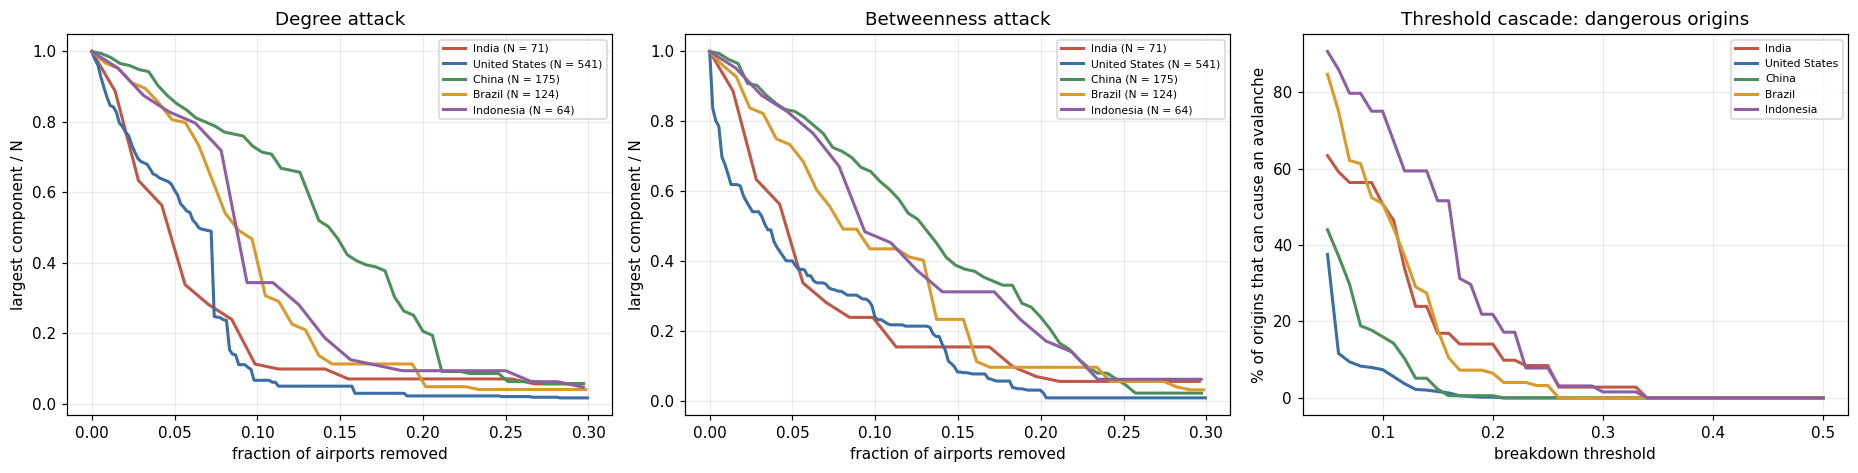

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sel = [("India", RED), ("United States", BLUE), ("China", GREEN), ("Brazil", ORANGE), ("Indonesia", PURPLE)]
for kind, ax in [("degree", axes[0]), ("betweenness", axes[1])]:
    for c, col in sel:
        g = nets[c]; n = g.number_of_nodes(); l = at.percolation_curves(g, rg.fast_order(g, kind))[0]; k = min(n, int(0.3 * n))
        ax.plot(np.arange(k + 1) / n, l[:k + 1] / n, color=col, lw=2, label=f"{c} (N = {n})")
    ax.set_xlabel("fraction of airports removed"); ax.set_ylabel("largest component / N"); ax.set_title(f"{kind.capitalize()} attack"); ax.legend(fontsize=7)
ax = axes[2]
tg = np.round(np.arange(0.05, 0.5001, 0.01), 2)
for c, col in sel:
    C = cs.Cascade(nets[c]); n = C.n
    ax.plot(tg, [np.mean([C.run([i], C.need(t))[0].sum() >= 0.5 * n for i in range(n)]) * 100 for t in tg], color=col, lw=2, label=c)
ax.set_xlabel("breakdown threshold"); ax.set_ylabel("% of origins that can cause an avalanche"); ax.set_title("Threshold cascade: dangerous origins"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading this.**
- **Relative to the US India is strongly hub-dominated** (its top hub reaches 64% of the airports, against 28%), but **relative to countries of its own size it is typical or even below the median** (median 74%; India is at the 38th percentile). India's two biggest airports, BOM (45) and DEL (43), have nearly equal degree, and the loss of the top hub alone leaves 90% of the survivors connected, because the other hub takes over; losing the **top three** leaves only 59% connected.
- **In the threshold cascade India is cascade-prone but typical of its peers:** half of its single failures can collapse it at threshold 0.10 (50.7%), the same as the peer median (50.8%), against 7.4% in the US. This is a property of **sparse networks** (Part F), not of India specifically.
- **In the load cascade India is at the safe end of its peer group:** the same critical spare capacity as the US (0.20, the 33rd percentile of the peers, whose median is 0.30) and the same share of dangerous origins.
- **Under targeted attack India is a little more fragile than its peers** (24th percentile for the removals needed under a degree attack, 0.056) but, relative to random failure, less extreme than the US (ratio 0.14 against 0.10).
- India's clustering (0.62) is the **highest of its peer group**.
- So the answer to "is India more fragile than the US?" is: **it depends on the measure, and mostly it reflects size and sparsity rather than anything specific to India**: yes in the threshold cascade and in hub dominance; no in the load cascade or in the targeted-to-random ratio; and among networks of its own size India is average.
- Caveat: India has only 71 airports in this 2014 snapshot (airlines and routes have changed a great deal since), so these are statements about that data version, not about today's network.

## Part H. Verdict

In [16]:
us_rank_hub = int(dom["hub dominance (kmax/(N-1))"].rank(ascending=False, method="min")["United States"])
rejected = ", ".join(ht.index[ht["power-law GOF p"] < 0.1])
ncm = int((cm_["modularity z vs degree-preserving null"] > 3).sum())
verdict = pd.DataFrame([
    ("(paper) one country, general conclusions", f"Tested on {len(domestic)} domestic networks plus Europe and the world", "gap addressed"),
    ("The network is hub-dominated", f"True qualitatively everywhere (negative assortativity in all {len(dom)}), but the US is among the *least* hub-dominated: top hub connects to {100 * us['hub dominance (kmax/(N-1))']:.0f}% of airports (rank {us_rank_hub} of {len(dom)}; median {100 * dom['hub dominance (kmax/(N-1))'].median():.0f}%); India {100 * P.loc['India', 'hub dominance (kmax/(N-1))']:.0f}%", "true, but the US is mild"),
    ("The biggest hub grows linearly with N (the anomalous-regime reading, M2)", f"No: k_max ~ N^{slope:.2f} (95% interval {lo:.2f} to {hi:.2f}) across {len(dom)} countries", "not supported"),
    ("Degrees follow a power law with gamma below 2 (anomalous regime)", f"A pure power law is rejected in only {n_rej} of {len(ht)} domestic networks ({rejected}); the median gamma is {ht['gamma (discrete MLE)'].median():.1f} and only {int((ht['gamma (discrete MLE)'] <= 2).sum())} countries have gamma at most 2; the US has the lowest ({ht.loc['United States', 'gamma (discrete MLE)']:.2f})", "US-specific"),
    ("Strong community structure beyond degrees (M3, M4)", f"Holds in {ncm} of {len(cm_)} domestic networks (the larger, geographically extended ones); absent in several of the smallest", "half of the countries"),
    ("Robust to random failure, fragile to targeted attack", f"Holds in {n_ok} of {len(att)} domestic networks with a gap of at least a factor 2 (median ratio {att['targeted / random (best attack)'].median():.2f}; US {att.loc['United States', 'targeted / random (best attack)']:.2f})", "near-universal"),
    ("Cascade vulnerability (threshold model)", f"Most countries are more cascade-prone than the US (worst-origin threshold median {dom['threshold cascade: worst-origin critical threshold'].median():.2f} vs US {dom.loc['United States', 'threshold cascade: worst-origin critical threshold']:.2f}); driven by sparsity (Spearman {rho.loc['threshold: worst-origin critical threshold', 'mean degree']:+.2f} with mean degree), not size", "US is not typical"),
    ("Cascade vulnerability (load model)", f"Critical spare capacity varies from {dom['load cascade: critical spare capacity alpha*'].min():.2f} to {dom['load cascade: critical spare capacity alpha*'].max():.2f} (median {dom['load cascade: critical spare capacity alpha*'].median():.2f}); the US ({dom.loc['United States', 'load cascade: critical spare capacity alpha*']:.2f}) is among the safest; alpha* is not significantly related to any structural property", "US is at the safe end"),
    ("What predicts losing connectivity when the top hub fails", f"Share of degree-1 airports ({rho.loc['survivors connected after top hub removed (lower = more fragile)', 'share of degree-1 airports']:+.2f}) and hub dominance ({rho.loc['survivors connected after top hub removed (lower = more fragile)', 'hub dominance']:+.2f})", "new finding"),
    ("Do the two cascade models agree on what makes a network fragile?", f"No: sparse networks are the most threshold-cascade-prone ({rho.loc['threshold: worst-origin critical threshold', 'mean degree']:+.2f} with mean degree), dense ones have the most load-cascade-dangerous origins ({rho.loc['load: share of dangerous origins at alpha=0', 'mean degree']:+.2f})", "new finding"),
    ("Is India more fragile than the US?", "Depends on the measure; mostly size and sparsity: yes in the threshold cascade and hub dominance, no in the load cascade or the targeted-to-random ratio; among its size peers India is typical", "mixed; India is typical for its size"),
], columns=["claim", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["claim", "what we find"], **{"text-align": "left", "white-space": "normal"})

claim,what we find,status
"(paper) one country, general conclusions",Tested on 24 domestic networks plus Europe and the world,gap addressed
The network is hub-dominated,"True qualitatively everywhere (negative assortativity in all 24), but the US is among the *least* hub-dominated: top hub connects to 28% of airports (rank 23 of 24; median 69%); India 64%","true, but the US is mild"
"The biggest hub grows linearly with N (the anomalous-regime reading, M2)",No: k_max ~ N^0.58 (95% interval 0.29 to 0.81) across 24 countries,not supported
Degrees follow a power law with gamma below 2 (anomalous regime),"A pure power law is rejected in only 5 of 24 domestic networks (United States, Indonesia, France, Turkey, Sweden); the median gamma is 2.4 and only 4 countries have gamma at most 2; the US has the lowest (1.73)",US-specific
"Strong community structure beyond degrees (M3, M4)","Holds in 12 of 24 domestic networks (the larger, geographically extended ones); absent in several of the smallest",half of the countries
"Robust to random failure, fragile to targeted attack",Holds in 23 of 24 domestic networks with a gap of at least a factor 2 (median ratio 0.20; US 0.10),near-universal
Cascade vulnerability (threshold model),"Most countries are more cascade-prone than the US (worst-origin threshold median 0.33 vs US 0.20); driven by sparsity (Spearman -0.85 with mean degree), not size",US is not typical
Cascade vulnerability (load model),Critical spare capacity varies from 0.00 to 1.00 (median 0.30); the US (0.20) is among the safest; alpha* is not significantly related to any structural property,US is at the safe end
What predicts losing connectivity when the top hub fails,Share of degree-1 airports (-0.80) and hub dominance (-0.66),new finding
Do the two cascade models agree on what makes a network fragile?,"No: sparse networks are the most threshold-cascade-prone (-0.85 with mean degree), dense ones have the most load-cascade-dangerous origins (+0.66)",new finding


## Checks

In [17]:
checks = [
    ("24 domestic networks of at least 30 airports; US largest with 541", len(domestic) == len(nets) and domestic[0] == "United States" and nets["United States"].number_of_nodes() == 541 and len(domestic) >= 20),
    ("India has a network with BOM as largest hub", "India" in nets and P.loc["India", "largest hub"] == "BOM"),
    ("US reproduces earlier milestones (C 0.494, L 3.20, diameter 7, hub ATL 153)", abs(P.loc["United States", "clustering C"] - 0.4944) < 1e-3 and abs(P.loc["United States", "path length L"] - 3.2) < 1e-2 and P.loc["United States", "diameter"] == 7 and P.loc["United States", "largest hub"] == "ATL" and P.loc["United States", "largest degree"] == 153),
    ("US threshold cascade matches M6 (hub 0.165, worst origin LAS 0.2) and load cascade M9 (alpha* 0.2, ORD)", P.loc["United States", "threshold cascade: critical threshold of the top hub"] == 0.165 and P.loc["United States", "threshold cascade: worst origin"] == "LAS" and abs(P.loc["United States", "load cascade: critical spare capacity alpha*"] - 0.2) < 1e-9 and P.loc["United States", "load cascade: most dangerous origin"] == "ORD"),
    ("k_max grows sub-linearly: interval excludes 1", hi < 1.0 and slope > 0.4),
    ("hub dominance falls with size", spearmanr(dom["airports"], dom["hub dominance (kmax/(N-1))"]).statistic < -0.5),
    ("targeted attack beats random by 2x in at least 23 of 24 domestic networks", (att["targeted / random (best attack)"] < 0.5).sum() >= len(att) - 1 and att["targeted / random (best attack)"].median() < 0.3),
    ("US is among the least hub-dominated", us_rank_hub >= len(dom) - 3),
    ("India is far more threshold-cascade prone than the US", P.loc["India", "threshold cascade: share of origins causing an avalanche at t = 0.10"] > 3 * P.loc["United States", "threshold cascade: share of origins causing an avalanche at t = 0.10"]),
    ("India and US have the same load-model alpha*", abs(P.loc["India", "load cascade: critical spare capacity alpha*"] - P.loc["United States", "load cascade: critical spare capacity alpha*"]) < 1e-9),
    ("the pure power law is rejected for the US and the world", P.loc["United States", "power-law GOF p"] < 0.05 and P.loc["World (international)", "power-law GOF p"] < 0.05),
]
failed = [lab for lab, ok in checks if not ok]
print(f"{len(checks) - len(failed)} of {len(checks)} checks passed")
assert not failed, failed
print("All M10 assertions passed.")

11 of 11 checks passed
All M10 assertions passed.


## Summary and take-aways

- **The paper's US result is not a general law.** Run on 24 countries, some qualitative conclusions are shared (negative degree assortativity in all 24; "robust to random failure, fragile to targeted attack" in 23 of 24), but several are specific to the US: it has the **lowest exponent** (gamma 1.73; the median country has 2.4 and only 4 of 24 have gamma at most 2) and one of the **lowest hub dominance** values (ATL reaches 28% of the airports, the median country's top hub 69%); a pure power law is rejected in only 5 of 24 countries; communities beyond what degrees explain appear in only half of them.
- **The biggest hub does not grow linearly with the network**: k_max ~ N^0.58 (95% interval 0.29 to 0.81), which excludes the "k_max ~ N" reading of the anomalous regime and settles the question left open in M2.
- **Cascade vulnerability is a property of structure, not of size or country, and the two models see different structures.** The threshold model penalises *sparse* networks (worst-origin critical threshold vs mean degree: -0.85); the load model penalises *denser* ones (share of dangerous origins at zero spare capacity vs mean degree: +0.66). The US is among the least threshold-cascade-prone countries and needs less spare capacity (0.20) than most (median 0.30).
- **Losing the biggest hub hurts most where there are many spokes and a dominant hub:** the share of survivors that stay connected falls with the share of degree-1 airports (-0.80) and hub dominance (-0.66).
- **India is typical of its size.** Compared with the US it is far more hub-dominated (64% vs 28%) and far more threshold-cascade-prone (51% of single failures vs 7% at threshold 0.10), but compared with similar-sized countries it is average on these measures, matches the US in the load cascade (alpha* 0.20) and has the highest clustering of its group.
- **Caveats:** 2014 snapshot of crowd-sourced routes; domestic networks only (international links are excluded, which fragments island and small countries); unweighted; small networks give noisy statistics; cross-country associations (n = 24) are exploratory.

**Next:** M11 turns the question around: given what breaks, how should the network be protected, rewired or recovered?